In [1]:
# LANGGRAPH

In [15]:
# BMI sequential chain

In [1]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Annotated, List
from langchain_ollama import ChatOllama
from langchain_core.prompts import PromptTemplate
from langchain_core.output_parsers import JsonOutputParser
from pydantic import Field, BaseModel

In [17]:
class BmiState(TypedDict):
    weight: Annotated[float,"This is the weight of the person (in kgs)"]
    height: Annotated[float,"This is the height of the person (in meters)"]
    bmi: Annotated[float,"This is the bmi of the person"]

In [18]:
def calculate_bmi(state: BmiState)-> BmiState:
    w = state['weight']
    h = state['height']
    bmi = round(w/(h**2),2)
    state['bmi']=bmi
    return state

In [19]:
workflow = StateGraph(BmiState)

In [20]:
# creating nodes
workflow.add_node('calculate_bmi',calculate_bmi)

#creating edges
workflow.add_edge(START,'calculate_bmi')
workflow.add_edge('calculate_bmi',END)

In [21]:
#compile
app = workflow.compile()

In [22]:
x : BmiState = {'weight':65,'height':1.78}

In [23]:
result = app.invoke(x)

In [24]:
result

{'weight': 65, 'height': 1.78, 'bmi': 20.52}

In [25]:
# Now let's make another bmi sequential chain with another field diet.

In [2]:
class DietState(TypedDict):
    weight: Annotated[float,"This is the weight of the person (in kgs)"]
    height: Annotated[float,"This is the height of the person (in meters)"]
    bmi: Annotated[float,"This is the bmi of the person"]
    diet: Annotated[List[str],'This is a list of things the person should eat']

In [3]:
# initialise graph
graph = StateGraph(DietState)

In [4]:
class DietOutput(BaseModel):
    diet: Annotated[List[str],Field(description='This is a list of foods I should eat as per my bmi. All the elements are atmost 2-3 words in this list.')]

parser = JsonOutputParser(pydantic_object=DietOutput)

def get_diet(state: DietState) -> DietState:
    w = state['weight']
    h = state['height']
    bmi = state['bmi']

    #prompt
    template = PromptTemplate(
        template = """You are a senior dietition. You will be given the weight, height and bmi of a person. Return a list of diet foods to take. \n
        Weight -> {weight}, Height -> {height}, BMI -> {bmi} \n {format_instructions}""",
        input_variables=['weight','height','bmi'],
        partial_variables={'format_instructions':parser.get_format_instructions()}
    )

    model = ChatOllama(model='qwen3.5:4b',think=False)

    chain = template | model | parser
    result = chain.invoke({'weight':w,'height':h,'bmi':bmi})
    state['diet']=result['diet']
    return state

In [5]:
def calc_bmi(state: DietState)-> DietState:
    w = state['weight']
    h = state['height']
    bmi = round(w/(h**2),2)
    state['bmi']=bmi
    return state

In [6]:
# nodes
graph.add_node('calc_bmi',calc_bmi)
graph.add_node('get_diet',get_diet)

# edges
graph.add_edge(START,'calc_bmi')
graph.add_edge('calc_bmi','get_diet')
graph.add_edge('get_diet',END)

In [7]:
app = graph.compile()

In [8]:
x : DietState = {'weight':65,'height':1.78}

In [9]:
res = app.invoke(x)

In [10]:
res

{'weight': 65,
 'height': 1.78,
 'bmi': 20.52,
 'diet': ['Grilled Chicken Breast',
  'Steamed Broccoli',
  'Roasted Sweet Potato',
  'Plain Oatmeal',
  'Greek Yogurt']}

In [22]:
app.get_graph().draw_ascii()

'+-----------+  \r\n| __start__ |  \r\n+-----------+  \r\n      *        \r\n      *        \r\n      *        \r\n+----------+   \r\n| calc_bmi |   \r\n+----------+   \r\n      *        \r\n      *        \r\n      *        \r\n+----------+   \r\n| get_diet |   \r\n+----------+   \r\n      *        \r\n      *        \r\n      *        \r\n +---------+   \r\n | __end__ |   \r\n +---------+   '

In [23]:
from IPython.display import Image, display

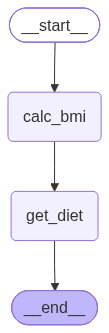

In [26]:
display(Image(app.get_graph().draw_mermaid_png()))